# Theoretical Network Validation

This notebook rigorously compares our empirical VARLiNGAM causal weights against 
established neurobiological theories (Haber's Spirals, NE arousal, 5HT/DA inhibition)
across long periods of baseline brain states.

**Key Features:**
1. Runs over the full baseline state (IFDN) or the pre-social baseline (Juvenile Intruder).
2. Employs 60-second sliding/chunked windows to stabilize VARLiNGAM over 100k+ frames.
3. Excludes all NaN/hardware-artifact frames natively using sanitized data.

In [1]:
import sys
from pathlib import Path
import pickle
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Add project root to path
try:
    project_root = Path(__file__).resolve().parents[2]
except NameError:
    project_root = Path("../../").resolve()
    
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from monoamine_interactions.notebooks.utils.photometry import motion_correct_biexponential
from monoamine_interactions.analysis.phase_1_causality import varlingam

In [2]:
# 1. Configuration
# ==========================================
DATASET = "baseline" # Select 'baseline' or 'social'

if DATASET == "baseline":
    pkl_path = project_root / "monoamine_interactions" / "data" / "sessions_sanitized.pkl"
elif DATASET == "social":
    pkl_path = project_root / "monoamine_interactions" / "data" / "sessions_jonathan_juvenile_intruder_sanitized.pkl"
else:
    raise ValueError(f"Unknown dataset: {DATASET}")

out_dir = project_root / "monoamine_interactions" / "outputs" / "07_theoretical_validation"
out_dir.mkdir(parents=True, exist_ok=True)

CHUNK_DUR_SEC = 60  # 60 seconds of data per VARLiNGAM chunk
LAG = 5
N_JOBS = -1

In [3]:
# 2. The Biological Dictionary
# ==========================================
# We define expected causal relationships here to compare against data.
# 1 = Positive (Excitation/Drive), -1 = Negative (Inhibition/Brake), 0 = None
EXPECTED_CAUSALITY = {
    # 1. 5HT & DA
    ("lNAc_5HT", "rNAc_DA"): -1,  # 5HT inhibits DA
    ("lNAc_DA", "rNAc_5HT"): 0,   # DA does not drive 5HT
    ("rNAc_5HT", "lNAc_DA"): -1,
    ("rNAc_DA", "lNAc_5HT"): 0,
    
    # 2. Arousal (NE)
    ("DRN_NE", "NAc_5HT"): 1,     # NE drives Raphe
    ("NAc_5HT", "DRN_NE"): 0,
    ("VTA_NE", "NAc_DA"): 1,      # NE drives VTA
    ("NAc_DA", "VTA_NE"): 0,
    
    # 3. Striatal Spirals
    ("VS", "DMS"): 1,             # Ventral to Medial
    ("DMS", "DLS"): 1,            # Medial to Lateral
    ("DMS", "VS"): 0,
    ("DLS", "DMS"): 0
}

# Group metadata for coloring
CATEGORY_MAP = {
    ("lNAc_5HT", "rNAc_DA"): "5HT/DA Inhibition",
    ("lNAc_DA", "rNAc_5HT"): "5HT/DA Inhibition",
    ("rNAc_5HT", "lNAc_DA"): "5HT/DA Inhibition",
    ("rNAc_DA", "lNAc_5HT"): "5HT/DA Inhibition",
    
    ("DRN_NE", "NAc_5HT"): "NE Arousal",
    ("NAc_5HT", "DRN_NE"): "NE Arousal",
    ("VTA_NE", "NAc_DA"): "NE Arousal",
    ("NAc_DA", "VTA_NE"): "NE Arousal",
    
    ("VS", "DMS"): "Haber's Spirals",
    ("DMS", "DLS"): "Haber's Spirals",
    ("DMS", "VS"): "Haber's Spirals",
    ("DLS", "DMS"): "Haber's Spirals"
}

In [4]:
# 3. Load & Preprocess Data
# ==========================================
print(f"Loading {pkl_path}...")
with open(pkl_path, "rb") as f:
    sessions = pickle.load(f)

# Deduplicate
unique_sessions = []
seen_pairs = set()
for s in sessions:
    csv = s.metadata.get('photometry_csv_path')
    animal = s.metadata.get('animal_id')
    pair = (csv, animal)
    if csv and pair not in seen_pairs:
        seen_pairs.add(pair)
        unique_sessions.append(s)
sessions = unique_sessions
print(f"Loaded {len(sessions)} unique biological animals.")

# Worker function for VARLiNGAM
def run_chunk(chunk_df, valid_regs):
    clean_chunk = chunk_df.dropna()
    if len(clean_chunk) < 100: return None
    
    try:
        res = varlingam.run_varlingam(clean_chunk, lags=LAG)
        adj = res["adjacency_matrices"][0]
        
        chunk_res = {}
        for i, r1 in enumerate(valid_regs):
            for j, r2 in enumerate(valid_regs):
                if i == j: continue
                # weight from r2 to r1
                chunk_res[(r2, r1)] = adj[i, j]
        return chunk_res
    except:
        return None

Loading /home/fsp585/Desktop/FiberphotometryCode/monoamine_interactions/data/sessions_sanitized.pkl...
Loaded 12 unique biological animals.


In [5]:
# 4. Extract Chunks & Compute Base State
# ==========================================
all_empirical_edges = []

for s in tqdm(sessions, desc="Analyzing Baseline States"):
    # Determine valid regions
    sm = s.metadata.get("signal_meta", {})
    region_map = {k: v.get("region") or v.get("brain_reg") for k, v in sm.items() if v.get("region") or v.get("brain_reg")}
    regions = list(set(region_map.values())) # Deduplicate
    if len(regions) < 2: continue
        
    df = getattr(s, 'all_data_df', None)
    if df is None or len(df) == 0:
        # Fallback to photometry dict if all_data_df isn't merged
        if '470' in s.photometry:
            df = s.photometry['470']
            
    if 'SystemTimestamp' not in df.columns: continue
        
    # Apply Social Epoch Slicing if necessary
    ts_array = df['SystemTimestamp'].values
    start_idx = 0
    end_idx = len(df)
    
    if DATASET == "social":
        tm = s.metadata.get("timing_meta", {})
        t_in = tm.get('inarena_min')
        t_hc = tm.get('home_cage_min')
        if pd.isna(t_in) or pd.isna(t_hc): continue
        
        t0 = ts_array[0]
        start_idx = np.abs(ts_array - (t0 + t_in * 60)).argmin()
        end_idx = np.abs(ts_array - (t0 + t_hc * 60)).argmin()
        
    if end_idx <= start_idx: continue
        
    # Extract DFF using either the precomputed or manually correcting
    dff_dict = {}
    valid_regs = []
    
    for r in regions:
        try:
            col = next((k for k, v in region_map.items() if v == r))
            
            # Use precomputed if available
            dff_col = f"{col}_dff"
            if dff_col in df.columns:
                trace = df[dff_col].values[start_idx:end_idx]
            else:
                raw = df[col].values[start_idx:end_idx]
                iso = s.photometry['415'][col].values[start_idx:end_idx]
                trace = motion_correct_biexponential(raw, iso)
                
            dff_dict[r] = trace
            valid_regs.append(r)
        except Exception as e:
            pass
            
    if len(valid_regs) < 2: continue
        
    # Build dataframe for chunking
    df_epoch = pd.DataFrame(dff_dict)
    
    # Calculate chunk size based on framerate
    fs = s.metadata.get('fs', 20.0) # default to 20 if missing
    frames_per_chunk = int(CHUNK_DUR_SEC * fs)
    
    # Split into chunks
    chunks = []
    for i in range(0, len(df_epoch), frames_per_chunk):
        chunk = df_epoch.iloc[i:i+frames_per_chunk]
        if len(chunk) >= frames_per_chunk * 0.8: # Must be at least 80% full
            chunks.append(chunk)
            
    if not chunks: continue
        
    # Run VARLiNGAM in parallel
    chunk_results = joblib.Parallel(n_jobs=N_JOBS)(
        joblib.delayed(run_chunk)(c, valid_regs) for c in chunks
    )
    
    # Aggregate over the whole epoch to find the "Base State" for this session
    session_edges = {}
    for res in chunk_results:
        if res is None: continue
        for pair, weight in res.items():
            if pair not in session_edges: session_edges[pair] = []
            session_edges[pair].append(weight)
            
    for pair, weights in session_edges.items():
        all_empirical_edges.append({
            'source': pair[0],
            'target': pair[1],
            'mean_weight': np.nanmean(weights),
            'std_weight': np.nanstd(weights),
            'n_chunks': len(weights),
            'session': s.metadata.get('photometry_csv_path', 'unknown'),
            'genotype': s.metadata.get('genotype', 'Unknown')
        })

df_empirical = pd.DataFrame(all_empirical_edges)

Analyzing Baseline States: 100%|██████████| 12/12 [00:02<00:00,  4.01it/s]


/home/fsp585/miniforge3/envs/kpms_gpu/lib/python3.10/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/fsp585/miniforge3/envs/kpms_gpu/lib/python3.10/site-packages/seaborn/categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(aggregator, agg_var)
/home/fsp585/miniforge3/envs/kpms_gpu/lib/python3.10/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a futur

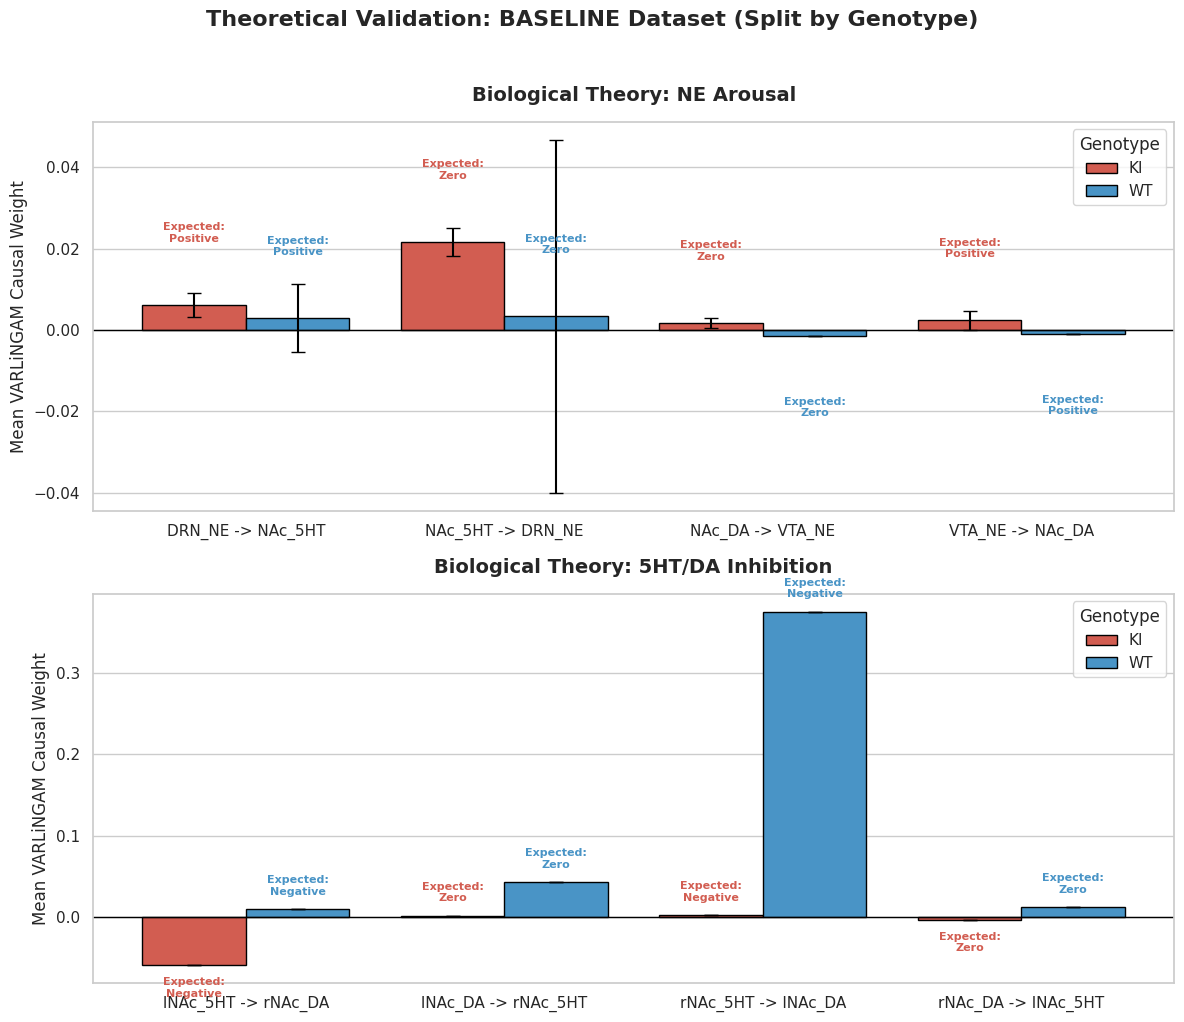


### Quantitative Validation Results (Genotype Split)

| Category | Pair | Genotype | Expected | Actual Weight | Std Error |
| :--- | :--- | :--- | :--- | :--- | :--- |
| 5HT/DA Inhibition | lNAc_5HT -> rNAc_DA | KI | Neg (-1) | -0.0590 | ±0.0000 |
| 5HT/DA Inhibition | lNAc_5HT -> rNAc_DA | WT | Neg (-1) | 0.0094 | ±0.0000 |
| 5HT/DA Inhibition | lNAc_DA -> rNAc_5HT | KI | Zero (0) | 0.0015 | ±0.0000 |
| 5HT/DA Inhibition | lNAc_DA -> rNAc_5HT | WT | Zero (0) | 0.0427 | ±0.0000 |
| 5HT/DA Inhibition | rNAc_5HT -> lNAc_DA | KI | Neg (-1) | 0.0024 | ±0.0000 |
| 5HT/DA Inhibition | rNAc_5HT -> lNAc_DA | WT | Neg (-1) | 0.3753 | ±0.0000 |
| 5HT/DA Inhibition | rNAc_DA -> lNAc_5HT | KI | Zero (0) | -0.0033 | ±0.0000 |
| 5HT/DA Inhibition | rNAc_DA -> lNAc_5HT | WT | Zero (0) | 0.0124 | ±0.0000 |
| NE Arousal | DRN_NE -> NAc_5HT | KI | Pos (+1) | 0.0062 | ±0.0083 |
| NE Arousal | DRN_NE -> NAc_5HT | WT | Pos (+1) | 0.0029 | ±0.0029 |
| NE Arousal | NAc_5HT -> DRN_NE | KI | Zero (0) | 0.0217

In [6]:
# 5. Match with Theory and Plot (Split by Genotype)
# ==========================================
if df_empirical.empty:
    print("No valid multi-region causal chunks found in this dataset.")
    sys.exit(0)

# Aggregate by pair AND genotype
df_agg = df_empirical.groupby(['source', 'target', 'genotype'])['mean_weight'].agg(['mean', 'std', 'count']).reset_index()

# Join with expectations
plot_data = []
for idx, row in df_agg.iterrows():
    pair = (row['source'], row['target'])
    if pair in EXPECTED_CAUSALITY:
        plot_data.append({
            'Pair': f"{pair[0]} -> {pair[1]}",
            'Genotype': row['genotype'],
            'Empirical_Weight': row['mean'],
            'Empirical_Error': row['std'] / np.sqrt(row['count']) if row['count'] > 1 else 0,
            'Expected_Direction': EXPECTED_CAUSALITY[pair],
            'Category': CATEGORY_MAP[pair]
        })

df_plot = pd.DataFrame(plot_data)

if df_plot.empty:
    print("None of the observed pairs matched our theoretical dictionary.")
    sys.exit(0)

# Plotting
sns.set_theme(style="whitegrid")
categories = df_plot['Category'].unique()
fig, axes = plt.subplots(len(categories), 1, figsize=(12, 5 * len(categories)))
if len(categories) == 1: axes = [axes]

for ax, cat in zip(axes, categories):
    cat_df = df_plot[df_plot['Category'] == cat].copy()
    
    # Define color palette for genotypes
    palette = {'WT': '#3498db', 'KI': '#e74c3c', 'Unknown': '#95a5a6'}
    
    # Create the grouped bar plot
    sns.barplot(
        data=cat_df,
        x='Pair',
        y='Empirical_Weight',
        hue='Genotype',
        ax=ax,
        palette=palette,
        edgecolor='black',
        errorbar=None # We plot our own error bars manually
    )
    
    # Add custom error bars
    # (sns doesn't handle custom pre-computed errors well in grouped plots easily)
    # We iterate over the patches to find x positions
    # Note: this is a bit hacky but works for seaborn grouped bars
    x_coords = []
    for p in ax.patches:
        x_coords.append(p.get_x() + p.get_width() / 2.)
    
    # Sort cat_df to match seaborn's internal plotting order (Genotype then Pair)
    # Seaborn plots hue first, then x. So it's KI(Pair1), KI(Pair2)... then WT(Pair1), WT(Pair2)...
    # Actually it's Hue1(X1, X2...), Hue2(X1, X2...)
    hue_order = [h for h in ['WT', 'KI'] if h in cat_df['Genotype'].unique()]
    x_order = sorted(cat_df['Pair'].unique())
    
    ordered_errors = []
    ordered_expected = []
    for h in hue_order:
        for x in x_order:
            sub = cat_df[(cat_df['Genotype'] == h) & (cat_df['Pair'] == x)]
            ordered_errors.append(sub['Empirical_Error'].values[0] if len(sub) > 0 else 0)
            ordered_expected.append(sub['Expected_Direction'].values[0] if len(sub) > 0 else 0)
    
    for i, (x, err, expected) in enumerate(zip(x_coords, ordered_errors, ordered_expected)):
        if i < len(ax.patches):
            p = ax.patches[i]
            y = p.get_height()
            if np.isnan(y): continue # Skip empty bars
            
            ax.errorbar(x, y, yerr=err, fmt='none', c='black', capsize=5)
            
            # Add expectation text
            text = "Expected:\nPositive" if expected == 1 else "Expected:\nNegative" if expected == -1 else "Expected:\nZero"
            offset = 0.015 if y >= 0 else -0.015
            va = 'bottom' if y >= 0 else 'top'
            color = p.get_facecolor()
            ax.text(x, y + offset, text, ha='center', va=va, fontsize=8, fontweight='bold', color=color)

    ax.axhline(0, color='black', linestyle='-', linewidth=1)
    ax.set_title(f"Biological Theory: {cat}", fontsize=14, pad=15, fontweight='bold')
    ax.set_ylabel("Mean VARLiNGAM Causal Weight")
    ax.set_xlabel("")
    ax.legend(title='Genotype', loc='upper right')

plt.suptitle(f"Theoretical Validation: {DATASET.upper()} Dataset (Split by Genotype)", y=1.02, fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(out_dir / f"theoretical_validation_{DATASET}_genotype_split.png", bbox_inches='tight', dpi=300)
plt.show()

# Print markdown table
print("\n### Quantitative Validation Results (Genotype Split)\n")
print("| Category | Pair | Genotype | Expected | Actual Weight | Std Error |")
print("| :--- | :--- | :--- | :--- | :--- | :--- |")
for _, row in df_plot.sort_values(['Category', 'Pair', 'Genotype']).iterrows():
    ex_str = "Pos (+1)" if row['Expected_Direction'] == 1 else "Neg (-1)" if row['Expected_Direction'] == -1 else "Zero (0)"
    print(f"| {row['Category']} | {row['Pair']} | {row['Genotype']} | {ex_str} | {row['Empirical_Weight']:.4f} | ±{row['Empirical_Error']:.4f} |")